# M10a · Is the LayerNorm adaptation low-rank across layers? (no training)

**Why.** The planned redesign replaces 50 independent LayerNorms (102,400 numbers) by **shared-basis LayerNorm modulation (SB-LN)**: all 50 LayerNorms share a learned set of r channel directions, and each LayerNorm only learns r coefficients for its scale and r for its shift:

γ_l = γ_l⁰ + B_γ a_l,  β_l = β_l⁰ + B_β b_l,  B_γ, B_β ∈ ℝ^{1024×r},  a_l, b_l ∈ ℝ^r

Trainable LayerNorm numbers: 2·1024·r + 2·50·r (r = 8 → 17,184 instead of 102,400). M2/M2b showed that a **random** subspace loses most of the adaptation; SB-LN uses a **learned** channel basis. Before building it we check on the models we already have whether their LayerNorm changes have this structure.

**What this notebook measures** (all on existing checkpoints; nothing is trained):

1. Stack the trained changes into two 50 × 1024 matrices, Δγ (scale) and Δβ (shift), and compute their singular values: how much of the change do the top r shared channel directions carry?
2. Two forms of the scale change: **additive** (γ⁰ + Δγ) and **relative** (γ⁰ ⊙ (1 + R)).
3. **Truncation test:** replace every LayerNorm by its rank-r reconstruction (head unchanged) and score FF++ test (seen, each generator, FaceShifter) and DFD. This is a *lower bound* for SB-LN: a model trained inside the subspace can compensate, a truncated one cannot.
4. **Private offsets (for the new latent space):** do GBLA's per-generator offsets δ_g lie in the same channel directions as the shared solution? If yes, private offsets can live in the r-dim coefficient space (100r numbers per generator instead of 104,450).
5. Stability: do M1, pooled (λ = ∞) and GBLA (λ = 0.01) find the same directions?

**Decision rule (printed in 6.3).** For GBLA λ = 0.01: the smallest r whose truncated model keeps seen AUC within 0.5, FaceShifter within 1.0 and DFD within 0.5 of the full model. That r (or the next larger one) is the SB-LN rank for M11.

| Section | What it does | Run time |
|---|---|---|
| 1–2 | settings, model, θ layout | ~2 min |
| 3 | singular value spectra, layer profile, basis stability | seconds |
| 4 | private offsets vs shared basis | seconds |
| 5 | truncation test on FF++ test (and DFD) | ~45 s per configuration on FF++, ~3 min on DFD |
| 6 | decision and summary | seconds |

## 1. Setup

### 1.1 Settings

Paths as in M8b/M9b. Nothing is written outside `runs/m10a/`.

In [1]:
# 1.1 Settings
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
RUNS_ROOT = DATA_ROOT / "runs"
FACES_FF = DATA_ROOT / "faces"
FACES_DFD = DATA_ROOT / "faces_dfd"
FF_INDEX = DATA_ROOT / "index" / "ffpp_c23.csv"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
M10A_DIR = RUNS_ROOT / "m10a"

ARCH, PRETRAINED = "ViT-L-14", "openai"
SEED = 0
EPOCH = 10
EVAL_BATCH = 256
LOAD_THREADS = 16

RANKS = [1, 2, 4, 8, 16, 32]               # 50 = full rank (exact model)
VARIANTS = ["additive", "relative"]         # form of the scale change; the shift is always additive
EVAL_MODELS = ["m1", "lam_inf", "lam_0.01"] # truncation test on FF++ test
RUN_DFD = True
DFD_MODELS = ["lam_0.01"]
DFD_RANKS = [4, 8, 16]
OFFSET_MODELS = ["lam_0.01", "lam_0.1"]     # GBLA runs whose private offsets are analysed
BASIS_RANKS = [4, 8, 16]

M1_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-DF-F2F-FS-NT_seed{SEED}"


def m4_run(tag):
    return RUNS_ROOT / "m4" / f"gbla_lam{tag}_{ARCH}_seed{SEED}"


# key: (display name, checkpoint kind, checkpoint path)
MODELS = {
    "m1": ("LNCLIP-DF repro (M1, epoch 10)", "state", M1_DIR / f"epoch_{EPOCH:02d}.pt"),
    "lam_inf": ("pooled, λ=∞ (M4)", "gbla", m4_run("inf") / f"epoch_{EPOCH:02d}.pt"),
    "lam_0.1": ("GBLA λ=0.1", "gbla", m4_run("0.1") / f"epoch_{EPOCH:02d}.pt"),
    "lam_0.01": ("GBLA λ=0.01 (ours)", "gbla", m4_run("0.01") / f"epoch_{EPOCH:02d}.pt"),
}
# FF++ video AUC of the full models (M2b/M4), used to check that every checkpoint loads correctly
REFERENCE = {"m1": {"seen": 97.60, "FSh": 88.19}, "lam_inf": {"seen": 96.41, "FSh": 90.53},
             "lam_0.1": {"seen": 95.66, "FSh": 92.48}, "lam_0.01": {"seen": 95.55, "FSh": 92.91}}
DFD_REFERENCE = {"m1": 95.88, "lam_inf": 96.05, "lam_0.1": 96.70, "lam_0.01": 96.71}   # M8b

M10A_DIR.mkdir(parents=True, exist_ok=True)
for k, (_, _, path) in MODELS.items():
    assert path.exists(), f"checkpoint missing: {k} -> {path}"
print("models:", list(MODELS), "   results ->", M10A_DIR)

models: ['m1', 'lam_inf', 'lam_0.1', 'lam_0.01']    results -> /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m10a


In [2]:
# 1.2 Imports and environment
import json, math, random, time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda"
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)
display(pd.Series({"torch": torch.__version__, "open_clip": open_clip.__version__,
                   "GPU": torch.cuda.get_device_name(0)}, name="value").to_frame())

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB


## 2. Model

### 2.1 Detector and checkpoints

Same detector as every earlier milestone. θ⁰ (pretrained LayerNorms) is read from the freshly built model before any checkpoint is loaded.

In [3]:
# 2.1 Detector (as in M1/M4/M8b/M9b) and parameter report
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        f = F.normalize(self.encoder(x).float(), dim=-1)
        return self.head(f), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE).eval()
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)
TOTAL = sum(p.numel() for p in model.parameters())
param_report = {"total": TOTAL, "trainable (deployed)": P, "frozen": TOTAL - P,
                "trainable %": round(100 * P / TOTAL, 4)}
display(pd.Series(param_report, name="parameters").to_frame())
assert P == 104_450, P

THETA0 = torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float().cpu()   # pretrained LayerNorms + untrained head


@torch.no_grad()
def set_flat(theta):
    theta = theta.to(DEVICE).float()
    assert theta.numel() == P, (theta.numel(), P)
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p).to(p.dtype))
        offset += n


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def load_theta(kind, path):
    obj = load(path)
    if kind == "state":
        state = obj.get("trainable", obj)
        return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES])
    if kind == "gbla":
        return obj.get("gbla", obj)["theta_s"].float()
    raise ValueError(kind)


THETAS = {k: load_theta(kind, path) for k, (_, kind, path) in MODELS.items()}
print({k: f"{v.numel():,}" for k, v in THETAS.items()})

,parameters
total,3.031818e+08
trainable (deployed),1.044500e+05
frozen,3.030774e+08
trainable %,3.450000e-02


{'m1': '104,450', 'lam_inf': '104,450', 'lam_0.1': '104,450', 'lam_0.01': '104,450'}


In [4]:
# 2.2 Image loading, prediction and AUC helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def load_images(paths, desc):
    images = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def fill(i):
        images[i] = read_rgb(paths[i])

    with ThreadPoolExecutor(LOAD_THREADS) as pool:
        list(tqdm(pool.map(fill, range(len(paths)), chunksize=64), total=len(paths), desc=desc))
    return images


@torch.no_grad()
def run_model(theta, images, desc="predict", want_features=False):
    """Fake probability per crop (linear head); optionally the L2-normalised CLS features (float16)."""
    set_flat(theta)
    probs, feats = [], []
    for s in tqdm(range(0, len(images), EVAL_BATCH), desc=desc, leave=False):
        x = torch.from_numpy(images[s:s + EVAL_BATCH]).to(DEVICE, non_blocking=True)
        x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, f = model(x)
        probs.append(logits.float().softmax(1)[:, 1].cpu())
        if want_features:
            feats.append(F.normalize(f.float(), dim=-1).half().cpu())
    probs = torch.cat(probs).numpy()
    return (probs, torch.cat(feats).numpy()) if want_features else probs


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


SEEN = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS", "NeuralTextures": "NT", "FaceShifter": "FSh"}


def ff_video_aucs(test_df, scores):
    """FF++ test video AUC (%): seen combined, each generator, FaceShifter. Each generator vs the same real test videos."""
    df = test_df.assign(score=scores)
    vid = df.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), score=("score", "mean"))
    out = {}
    for name, gens in [("seen", SEEN)] + [(SHORT[g], [g]) for g in SEEN + ["FaceShifter"]]:
        sub = vid[vid.generator.isin(["original", *gens])]
        out[name] = 100 * auc(sub.label, sub.score)
    return out


def video_auc(index_df, scores):
    """Video AUC (%) for DFD / UADFV: video score = mean frame score."""
    vid = index_df.assign(score=scores).groupby("video_id", as_index=False).agg(label=("label", "first"), score=("score", "mean"))
    return 100 * auc(vid.label, vid.score)

### 2.3 Layout of θ: the 50 LayerNorms and the head

θ is the flat vector of 104,450 trainable numbers (M4 order). Here it is split into Γ (50 × 1024, all scales γ), Β (50 × 1024, all shifts β) and the head (2,050). Rows are in network order: `ln_pre`, then `ln_1`, `ln_2` of blocks 0–23, then `ln_post`.

The **relative** form divides by γ⁰. CLIP has a few scale entries near 0, so the denominator is clipped to magnitude ≥ 1e-3 (sign kept); the reconstruction uses the same clipped value, so the full-rank reconstruction is exact.

In [5]:
# 2.3 Layout of theta
SLICES, offset = {}, 0
for n, p in PARAMS:
    SLICES[n] = slice(offset, offset + p.numel())
    offset += p.numel()
LN_MODULES = [n[:-len(".weight")] for n, _ in PARAMS if n.endswith(".weight") and not n.startswith("head")]
assert len(LN_MODULES) == 50, len(LN_MODULES)
GAMMA_IDX = torch.stack([torch.arange(SLICES[m + ".weight"].start, SLICES[m + ".weight"].stop) for m in LN_MODULES])
BETA_IDX = torch.stack([torch.arange(SLICES[m + ".bias"].start, SLICES[m + ".bias"].stop) for m in LN_MODULES])
HEAD_IDX = torch.cat([torch.arange(SLICES[n].start, SLICES[n].stop) for n in PARAM_NAMES if n.startswith("head")])
assert GAMMA_IDX.shape == BETA_IDX.shape == (50, 1024) and HEAD_IDX.numel() == 2050


def ln_label(m):
    parts = m.split(".")
    return parts[-1] if "resblocks" not in parts else f"b{parts[parts.index('resblocks') + 1]}.{parts[-1]}"


LN_LABELS = [ln_label(m) for m in LN_MODULES]
G0, B0 = THETA0[GAMMA_IDX].double(), THETA0[BETA_IDX].double()
EPS_REL = 1e-3
G0_SAFE = torch.where(G0.abs() < EPS_REL, EPS_REL * torch.where(G0 < 0, -1.0, 1.0).double(), G0)

print("first / last LayerNorms:", LN_LABELS[:3], "...", LN_LABELS[-3:])
display(pd.Series({"gamma0 min |value|": float(G0.abs().min()), "gamma0 entries with |value| < 1e-3": int((G0.abs() < EPS_REL).sum()),
                   "gamma0 mean": float(G0.mean()), "beta0 mean |value|": float(B0.abs().mean())}, name="pretrained LayerNorms").to_frame())


def change_matrices(theta):
    """Delta-gamma (additive), R (relative) and Delta-beta, each 50 x 1024, float64."""
    g, b = theta[GAMMA_IDX].double(), theta[BETA_IDX].double()
    return {"additive": g - G0, "relative": (g - G0) / G0_SAFE, "beta": b - B0}


def svd(D):
    U, S, Vh = torch.linalg.svd(D, full_matrices=False)
    return U, S, Vh


def truncate(D, r):
    U, S, Vh = svd(D)
    r = min(r, len(S))
    return (U[:, :r] * S[:r]) @ Vh[:r]


def truncated_theta(theta, r, variant):
    """LayerNorms replaced by their rank-r reconstruction (separate bases for scale and shift); head unchanged."""
    ch = change_matrices(theta)
    g_new = G0 + truncate(ch["additive"], r) if variant == "additive" else G0 + G0_SAFE * truncate(ch["relative"], r)
    b_new = B0 + truncate(ch["beta"], r)
    t = theta.clone()
    t[GAMMA_IDX.reshape(-1)] = g_new.reshape(-1).float()
    t[BETA_IDX.reshape(-1)] = b_new.reshape(-1).float()
    return t


def sbln_params(r, head=2050):
    return 2 * 1024 * r + 2 * 50 * r + head


for k in MODELS:   # full-rank reconstruction must give back the model exactly
    for v in VARIANTS:
        assert torch.allclose(truncated_theta(THETAS[k], 50, v), THETAS[k], atol=1e-5), (k, v)
print("full-rank reconstruction is exact for every model and variant")

first / last LayerNorms: ['ln_pre', 'b0.ln_1', 'b0.ln_2'] ... ['b23.ln_1', 'b23.ln_2', 'ln_post']


,pretrained LayerNorms
gamma0 min |value|,1.354242e-07
gamma0 entries with |value| < 1e-3,2.730000e+02
gamma0 mean,1.358824e+00
beta0 mean |value|,1.451643e-01


full-rank reconstruction is exact for every model and variant


## 3. Structure of the trained LayerNorm changes

### 3.1 Singular value spectra

Share of the squared change (energy) carried by the top r shared channel directions, per model and matrix. A random 50 × 1024 matrix would need r ≈ 40 for 80%; a strongly shared structure reaches 80–90% at r ≤ 8.

Frobenius norm   r=1   r=2   r=4  \
model                          matrix                                          
LNCLIP-DF repro (M1, epoch 10) Δγ additive            16.8  10.0  16.6  24.6   
                               Δγ relative           591.4  61.0  81.3  97.6   
                               Δβ                     16.0  19.1  27.1  37.0   
pooled, λ=∞ (M4)               Δγ additive            16.6  12.3  19.8  28.7   
                               Δγ relative           573.7  69.9  92.3  99.0   
                               Δβ                     15.7  19.9  29.2  40.2   
GBLA λ=0.1                     Δγ additive            16.0  12.1  20.2  29.3   
                               Δγ relative           561.5  64.6  89.0  98.5   
                               Δβ                     15.3  20.9  30.3  41.2   
GBLA λ=0.01 (ours)             Δγ additive            15.7  11.6  20.1  29.3   
                               Δγ relative           648.0  76.0  91.0  97.4   
                               Δβ                     15.2  21.5  31.3  41.9   

                                              r=8   r=16   r=32  
model                          matrix                            
LNCLIP-DF repro (M1, epoch 10) Δγ additive   37.1   58.0   87.9  
                               Δγ relative  100.0  100.0  100.0  
                               Δβ            49.4   66.2   89.9  
pooled, λ=∞ (M4)               Δγ additive   42.1   62.6   90.4  
                               Δγ relative  100.0  100.0  100.0  
                               Δβ            52.8   69.3   91.4  
GBLA λ=0.1                     Δγ additive   42.4   62.4   89.8  
                               Δγ relative  100.0  100.0  100.0  
                               Δβ            53.8   69.7   91.1  
GBLA λ=0.01 (ours)             Δγ additive   42.5   62.6   90.1  
                               Δγ relative  100.0  100.0  100.0  
                               Δβ            54.3   70.1   91.4

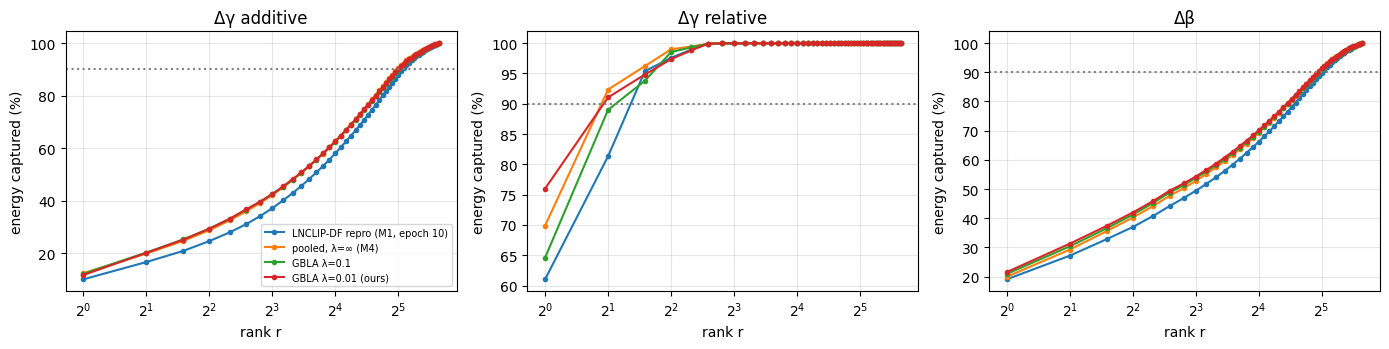

In [6]:
# 3.1 Spectra
CHANGES = {k: change_matrices(THETAS[k]) for k in MODELS}
SPECTRA = {(k, m): svd(D)[1] for k, ch in CHANGES.items() for m, D in ch.items()}


def energy(S, r):
    return float((S[:r] ** 2).sum() / (S ** 2).sum())


rows = []
for (k, m), S in SPECTRA.items():
    row = {"model": MODELS[k][0], "matrix": {"additive": "Δγ additive", "relative": "Δγ relative", "beta": "Δβ"}[m],
           "Frobenius norm": float((S ** 2).sum().sqrt())}
    row.update({f"r={r}": 100 * energy(S, r) for r in RANKS})
    rows.append(row)
spectra_table = pd.DataFrame(rows).set_index(["model", "matrix"])
display(spectra_table.round(1))
spectra_table.to_csv(M10A_DIR / "energy_by_rank.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, m, title in zip(axes, ["additive", "relative", "beta"], ["Δγ additive", "Δγ relative", "Δβ"]):
    for k in MODELS:
        S = SPECTRA[(k, m)]
        ax.plot(range(1, len(S) + 1), (S ** 2).cumsum(0) / (S ** 2).sum() * 100, marker=".", label=MODELS[k][0])
    ax.set_title(title); ax.set_xlabel("rank r"); ax.set_ylabel("energy captured (%)"); ax.set_xscale("log", base=2)
    ax.axhline(90, ls=":", c="gray"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(M10A_DIR / "spectra.png", dpi=150); plt.show()

### 3.2 Which LayerNorms move?

Norm of the change of each LayerNorm (GBLA λ = 0.01 and M1). If a few layers dominate, the per-layer coefficients matter more than the basis size.

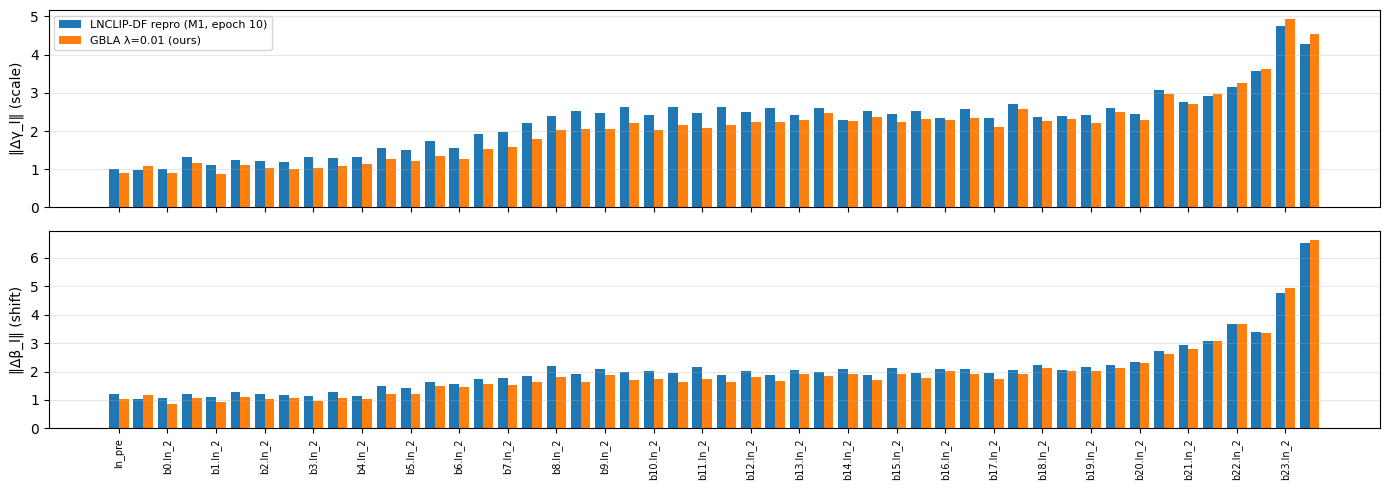

‖Δγ‖ GBLA        ‖Δβ‖ GBLA       
             mean    max      mean    max
kind                                     
ln_1        2.024  3.633     1.747  3.353
ln_2        2.012  4.921     1.890  4.948
ln_post     4.529  4.529     6.616  6.616
ln_pre      0.900  0.900     1.038  1.038

In [7]:
# 3.2 Layer profile
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
x = np.arange(50)
for ax, m, title in zip(axes, ["additive", "beta"], ["‖Δγ_l‖ (scale)", "‖Δβ_l‖ (shift)"]):
    for k, off in [("m1", -0.2), ("lam_0.01", 0.2)]:
        ax.bar(x + off, CHANGES[k][m].norm(dim=1).numpy(), width=0.4, label=MODELS[k][0])
    ax.set_ylabel(title); ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=8)
axes[1].set_xticks(x[::2]); axes[1].set_xticklabels(LN_LABELS[::2], rotation=90, fontsize=7)
plt.tight_layout(); plt.savefig(M10A_DIR / "layer_profile.png", dpi=150); plt.show()

prof = pd.DataFrame({"LN": LN_LABELS, "‖Δγ‖ GBLA": CHANGES["lam_0.01"]["additive"].norm(dim=1).numpy(),
                     "‖Δβ‖ GBLA": CHANGES["lam_0.01"]["beta"].norm(dim=1).numpy()})
prof["kind"] = [l.split(".")[-1] for l in LN_LABELS]
display(prof.groupby("kind")[["‖Δγ‖ GBLA", "‖Δβ‖ GBLA"]].agg(["mean", "max"]).round(3))
prof.to_csv(M10A_DIR / "layer_profile.csv", index=False)

### 3.3 Do different training runs find the same channel directions?

Overlap of the top-r channel bases (right singular vectors) of two models: ‖V_aᵀ V_b‖²_F / r. 1 = same subspace; a random pair of r-dim subspaces of ℝ¹⁰²⁴ gives about r / 1024. High overlap means the basis is a property of the task, not of one run.

In [8]:
# 3.3 Basis stability
def channel_basis(D, r):
    return svd(D)[2][:r].T          # 1024 x r


def overlap(Va, Vb):
    return float((Va.T @ Vb).pow(2).sum() / Va.shape[1])


rows = []
keys = list(MODELS)
for m in ["additive", "beta"]:
    for r in BASIS_RANKS:
        for i, a in enumerate(keys):
            for b in keys[i + 1:]:
                rows.append({"matrix": "Δγ" if m == "additive" else "Δβ", "r": r, "pair": f"{a} vs {b}",
                             "overlap": overlap(channel_basis(CHANGES[a][m], r), channel_basis(CHANGES[b][m], r)),
                             "random baseline": r / 1024})
stability = pd.DataFrame(rows)
display(stability.pivot_table(index=["matrix", "pair"], columns="r", values="overlap").round(3))
stability.to_csv(M10A_DIR / "basis_stability.csv", index=False)

r                              4      8      16
matrix pair                                    
Δβ     lam_0.1 vs lam_0.01  0.953  0.927  0.836
       lam_inf vs lam_0.01  0.915  0.811  0.771
       lam_inf vs lam_0.1   0.937  0.829  0.767
       m1 vs lam_0.01       0.831  0.699  0.647
       m1 vs lam_0.1        0.865  0.721  0.669
       m1 vs lam_inf        0.847  0.712  0.597
Δγ     lam_0.1 vs lam_0.01  0.907  0.788  0.789
       lam_inf vs lam_0.01  0.860  0.750  0.686
       lam_inf vs lam_0.1   0.882  0.753  0.678
       m1 vs lam_0.01       0.693  0.517  0.518
       m1 vs lam_0.1        0.734  0.550  0.584
       m1 vs lam_inf        0.698  0.495  0.467

## 4. Private offsets and the shared basis

For the redesign, each generator's private offset would live in the **coefficient space** of the shared basis (100r numbers) instead of the full 104,450. That is only reasonable if GBLA's existing offsets δ_g already point mostly along the shared solution's channel directions.

For each generator: the LayerNorm part of δ_g as Δγ_g, Δβ_g (50 × 1024), and the share of their energy inside the top-r channel basis of θ_s (`in θ_s basis`), next to the random baseline r / 1024 and the share captured by δ_g's own top-r directions (`own top-r`). Also the share of ‖δ_g‖² that sits in the head.

In [9]:
# 4. Private offsets vs the shared basis
rows = []
for k in OFFSET_MODELS:
    obj = load(MODELS[k][2])
    deltas = obj.get("gbla", obj)["delta"]
    for g, d in deltas.items():
        d = d.float()
        dg, db = d[GAMMA_IDX].double(), d[BETA_IDX].double()
        row = {"model": MODELS[k][0], "generator": g, "‖δ_g‖": float(d.norm()),
               "head share of ‖δ_g‖² (%)": 100 * float(d[HEAD_IDX].pow(2).sum() / d.pow(2).sum())}
        for r in BASIS_RANKS:
            Vg, Vb = channel_basis(CHANGES[k]["additive"], r), channel_basis(CHANGES[k]["beta"], r)
            row[f"Δγ_g in θ_s basis r={r} (%)"] = 100 * float((dg @ Vg).pow(2).sum() / dg.pow(2).sum())
            row[f"Δβ_g in θ_s basis r={r} (%)"] = 100 * float((db @ Vb).pow(2).sum() / db.pow(2).sum())
        row["Δγ_g own top-8 (%)"] = 100 * energy(svd(dg)[1], 8)
        row["Δβ_g own top-8 (%)"] = 100 * energy(svd(db)[1], 8)
        rows.append(row)
offsets = pd.DataFrame(rows).set_index(["model", "generator"])
display(offsets.round(2))
print("random baseline for r = 4 / 8 / 16:", [round(100 * r / 1024, 2) for r in BASIS_RANKS], "%")
offsets.to_csv(M10A_DIR / "private_offsets_vs_basis.csv")

‖δ_g‖  head share of ‖δ_g‖² (%)  \
model              generator                                         
GBLA λ=0.01 (ours) Deepfakes        0.82                     20.51   
                   Face2Face        1.32                      4.85   
                   FaceSwap         1.01                     10.62   
                   NeuralTextures   1.49                      1.90   
GBLA λ=0.1         Deepfakes        0.24                     34.50   
                   Face2Face        0.26                     20.43   
                   FaceSwap         0.32                     17.67   
                   NeuralTextures   0.42                      1.85   

                                   Δγ_g in θ_s basis r=4 (%)  \
model              generator                                   
GBLA λ=0.01 (ours) Deepfakes                            0.94   
                   Face2Face                            1.03   
                   FaceSwap                             0.71   
                   NeuralTextures                       0.77   
GBLA λ=0.1         Deepfakes                            1.00   
                   Face2Face                            0.65   
                   FaceSwap                             0.86   
                   NeuralTextures                       0.82   

                                   Δβ_g in θ_s basis r=4 (%)  \
model              generator                                   
GBLA λ=0.01 (ours) Deepfakes                            0.55   
                   Face2Face                            0.60   
                   FaceSwap                             0.52   
                   NeuralTextures                       0.90   
GBLA λ=0.1         Deepfakes                            0.84   
                   Face2Face                            0.64   
                   FaceSwap                             0.83   
                   NeuralTextures                       0.90   

                                   Δγ_g in θ_s basis r=8 (%)  \
model              generator                                   
GBLA λ=0.01 (ours) Deepfakes                            1.38   
                   Face2Face                            2.37   
                   FaceSwap                             1.23   
                   NeuralTextures                       1.61   
GBLA λ=0.1         Deepfakes                            1.32   
                   Face2Face                            1.02   
                   FaceSwap                             1.28   
                   NeuralTextures                       1.33   

                                   Δβ_g in θ_s basis r=8 (%)  \
model              generator                                   
GBLA λ=0.01 (ours) Deepfakes                            1.00   
                   Face2Face                            1.33   
                   FaceSwap                             0.90   
                   NeuralTextures                       1.49   
GBLA λ=0.1         Deepfakes                            1.26   
                   Face2Face                            1.24   
                   FaceSwap                             1.28   
                   NeuralTextures                       1.42   

                                   Δγ_g in θ_s basis r=16 (%)  \
model              generator                                    
GBLA λ=0.01 (ours) Deepfakes                             2.37   
                   Face2Face                             5.08   
                   FaceSwap                              2.08   
                   NeuralTextures                        4.04   
GBLA λ=0.1         Deepfakes                             2.05   
                   Face2Face                             2.17   
                   FaceSwap                              1.92   
                   NeuralTextures                        2.55   

                                   Δβ_g in θ_s basis r=16 (%)  \
model              generator                          

random baseline for r = 4 / 8 / 16: [0.39, 0.78, 1.56] %


## 5. Truncation test

Every LayerNorm replaced by its rank-r reconstruction (scale and shift each with their own r directions); the head is the trained head. `full` = the original model; its FF++ numbers must match M2b/M4 (load check, tolerance 0.3).

Results are appended to `runs/m10a/truncation_results.csv` after every configuration; finished configurations are skipped when the cell is re-run.

In [10]:
# 5.1 FF++ test
ff = pd.read_csv(FF_INDEX, dtype={"video_id": str, "target_id": str, "source_id": str}, keep_default_na=False)
ff_test = ff[ff.split == "test"].reset_index(drop=True)
print(f"FF++ test crops: {len(ff_test):,}")
FF_TEST_IMAGES = load_images([str(FACES_FF / p) for p in ff_test.path], desc="FF++ test")

RESULTS_CSV = M10A_DIR / "truncation_results.csv"
results = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()


def done(key):
    return len(results) and (results.key == key).any()


def record(row):
    global results
    results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)
    results.to_csv(RESULTS_CSV, index=False)


configs = [(k, "full", 50) for k in EVAL_MODELS] + [(k, v, r) for k in EVAL_MODELS for v in VARIANTS for r in RANKS]
for k, v, r in configs:
    key = f"ff|{k}|{v}|{r}"
    if done(key):
        continue
    theta = THETAS[k] if v == "full" else truncated_theta(THETAS[k], r, v)
    t0 = time.time()
    aucs = ff_video_aucs(ff_test, run_model(theta, FF_TEST_IMAGES, desc=key))
    record({"key": key, "set": "FF++", "model": k, "variant": v, "rank": r,
            "LN trainable if SB-LN": 2 * 1024 * r + 2 * 50 * r if v != "full" else 102_400, **aucs,
            "seconds": round(time.time() - t0)})
    print(f"{key}: seen {aucs['seen']:.2f}  NT {aucs['NT']:.2f}  FSh {aucs['FSh']:.2f}")

full = results[(results.set == "FF++") & (results.variant == "full")].set_index("model")
check = pd.DataFrame({k: {"seen": full.loc[k, "seen"], "expected seen": REFERENCE[k]["seen"],
                          "FSh": full.loc[k, "FSh"], "expected FSh": REFERENCE[k]["FSh"]} for k in EVAL_MODELS}).T
check["ok"] = ((check.seen - check["expected seen"]).abs() < 0.3) & ((check.FSh - check["expected FSh"]).abs() < 0.3)
display(check)
assert check.ok.all(), "a checkpoint does not reproduce its FF++ results"

FF++ test crops: 26,880


FF++ test: 100%|██████████| 26880/26880 [00:23<00:00, 1146.51it/s]
                                                                

ff|m1|full|50: seen 97.60  NT 93.88  FSh 88.19


ff|lam_inf|full|50: seen 96.41  NT 87.90  FSh 90.53


ff|lam_0.01|full|50: seen 95.55  NT 85.06  FSh 92.91


ff|m1|additive|1: seen 78.88  NT 57.54  FSh 72.22


... (32 outputs left out)

ff|lam_0.01|relative|8: seen 77.62  NT 53.68  FSh 66.12


ff|lam_0.01|relative|16: seen 81.45  NT 54.34  FSh 69.23


ff|lam_0.01|relative|32: seen 92.22  NT 72.83  FSh 91.35


,seen,expected seen,FSh,expected FSh,ok
m1,97.598214,97.60,88.193878,88.19,True
lam_inf,96.405612,96.41,90.530612,90.53,True
lam_0.01,95.552296,95.55,92.913265,92.91,True


In [11]:
# 5.2 DFD (selected configurations)
if RUN_DFD:
    dfd = pd.read_csv(DFD_INDEX)
    DFD_IMAGES = load_images([str(FACES_DFD / p) for p in dfd.path], desc="DFD crops")
    configs = [(k, "full", 50) for k in DFD_MODELS] + [(k, v, r) for k in DFD_MODELS for v in VARIANTS for r in DFD_RANKS]
    for k, v, r in configs:
        key = f"dfd|{k}|{v}|{r}"
        if done(key):
            continue
        theta = THETAS[k] if v == "full" else truncated_theta(THETAS[k], r, v)
        t0 = time.time()
        a = video_auc(dfd, run_model(theta, DFD_IMAGES, desc=key))
        record({"key": key, "set": "DFD", "model": k, "variant": v, "rank": r, "DFD": a, "seconds": round(time.time() - t0)})
        print(f"{key}: DFD video AUC {a:.2f}")
    for k in DFD_MODELS:
        got = float(results[(results.key == f"dfd|{k}|full|50")].DFD.iloc[0])
        assert abs(got - DFD_REFERENCE[k]) < 0.3, (k, got, DFD_REFERENCE[k])
    del DFD_IMAGES

DFD crops: 100%|██████████| 109454/109454 [01:10<00:00, 1547.91it/s]
                                                                       

dfd|lam_0.01|full|50: DFD video AUC 96.71


dfd|lam_0.01|additive|4: DFD video AUC 88.06


dfd|lam_0.01|additive|8: DFD video AUC 88.66


dfd|lam_0.01|additive|16: DFD video AUC 90.72


dfd|lam_0.01|relative|4: DFD video AUC 89.11


dfd|lam_0.01|relative|8: DFD video AUC 89.06


dfd|lam_0.01|relative|16: DFD video AUC 91.86


## 6. Results and decision

### 6.1 Tables

In [12]:
# 6.1 Tables
ffr = results[results.set == "FF++"].copy()
for k in EVAL_MODELS:
    print(f"\n=== {MODELS[k][0]} (FF++ test video AUC %) ===")
    sub = ffr[ffr.model == k].set_index(["variant", "rank"])[["LN trainable if SB-LN", "seen", "DF", "F2F", "FS", "NT", "FSh"]]
    display(sub.sort_index().round(2))
if RUN_DFD:
    print("\n=== DFD video AUC % ===")
    display(results[results.set == "DFD"].set_index(["model", "variant", "rank"])[["DFD"]].sort_index().round(2))


=== LNCLIP-DF repro (M1, epoch 10) (FF++ test video AUC %) ===


LN trainable if SB-LN   seen     DF    F2F     FS     NT    FSh
variant  rank                                                                 
additive 1                    2148.0  78.88  93.88  71.54  92.55  57.54  72.22
         2                    4296.0  79.62  94.05  72.56  92.97  58.89  72.72
         4                    8592.0  79.14  93.73  71.68  92.97  58.16  71.81
         8                   17184.0  80.02  94.66  73.37  94.33  57.71  71.41
         16                  34368.0  83.08  95.79  80.39  96.26  59.88  72.77
         32                  68736.0  92.23  98.40  94.20  99.16  77.15  83.42
full     50                 102400.0  97.60  99.22  98.09  99.20  93.88  88.19
relative 1                    2148.0  73.93  88.96  65.51  85.27  56.00  66.97
         2                    4296.0  79.22  94.19  72.19  92.68  57.80  71.08
         4                    8592.0  79.14  94.24  71.89  92.70  57.71  71.00
         8                   17184.0  79.74  95.06  72.82  93.82  57.26  71.08
         16                  34368.0  84.04  97.31  81.44  97.23  60.17  73.79
         32                  68736.0  95.21  99.06  95.86  99.29  86.62  85.63


=== pooled, λ=∞ (M4) (FF++ test video AUC %) ===


LN trainable if SB-LN   seen     DF    F2F     FS     NT    FSh
variant  rank                                                                 
additive 1                    2148.0  78.31  94.81  70.45  92.81  55.16  70.51
         2                    4296.0  78.78  94.88  71.07  93.09  56.06  70.29
         4                    8592.0  77.72  94.02  68.92  92.85  55.10  68.18
         8                   17184.0  78.64  94.29  70.71  94.05  55.52  68.80
         16                  34368.0  85.38  98.08  85.51  98.43  59.50  83.20
         32                  68736.0  91.04  98.89  96.04  99.41  69.83  83.64
full     50                 102400.0  96.41  99.72  98.66  99.34  87.90  90.53
relative 1                    2148.0  70.67  85.97  62.16  82.04  52.52  65.76
         2                    4296.0  78.52  95.17  70.57  93.19  55.14  69.84
         4                    8592.0  78.31  94.89  70.10  93.27  54.98  69.20
         8                   17184.0  79.32  95.59  71.84  94.73  55.12  70.13
         16                  34368.0  87.40  98.83  88.74  98.99  63.04  85.22
         32                  68736.0  92.34  99.08  96.45  99.34  74.47  84.91


=== GBLA λ=0.01 (ours) (FF++ test video AUC %) ===


LN trainable if SB-LN   seen     DF    F2F     FS     NT    FSh
variant  rank                                                                 
additive 1                    2148.0  77.43  94.20  69.16  92.19  54.16  68.75
         2                    4296.0  77.96  94.36  69.95  92.64  54.88  68.83
         4                    8592.0  77.35  93.90  68.77  92.59  54.14  67.18
         8                   17184.0  77.47  93.41  69.24  92.46  54.78  66.25
         16                  34368.0  81.12  95.90  76.60  96.11  55.86  69.01
         32                  68736.0  90.96  99.32  96.19  99.68  68.63  91.18
full     50                 102400.0  95.55  99.43  98.55  99.17  85.06  92.91
relative 1                    2148.0  73.43  90.29  64.17  85.92  53.35  64.47
         2                    4296.0  77.47  94.22  69.59  92.20  53.87  67.31
         4                    8592.0  77.41  94.13  69.30  92.47  53.74  66.66
         8                   17184.0  77.62  94.35  69.57  92.89  53.68  66.12
         16                  34368.0  81.45  97.07  77.52  96.87  54.34  69.23
         32                  68736.0  92.22  99.42  96.93  99.70  72.83  91.35


=== DFD video AUC % ===


DFD
model    variant  rank       
lam_0.01 additive 4     88.06
                  8     88.66
                  16    90.72
         full     50    96.71
         relative 4     89.11
                  8     89.06
                  16    91.86

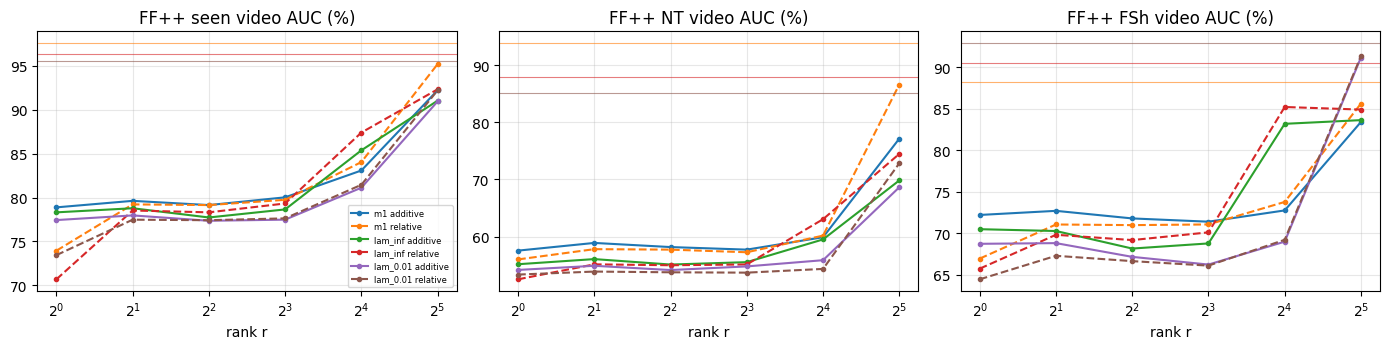

In [13]:
# 6.2 AUC against rank
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, ["seen", "NT", "FSh"]):
    for k in EVAL_MODELS:
        f = ffr[(ffr.model == k) & (ffr.variant == "full")][col].iloc[0]
        for v, ls in [("additive", "-"), ("relative", "--")]:
            s = ffr[(ffr.model == k) & (ffr.variant == v)].sort_values("rank")
            ax.plot(s["rank"], s[col], ls=ls, marker="o", ms=3, label=f"{k} {v}")
        ax.axhline(f, lw=0.8, c=ax.lines[-1].get_color(), alpha=0.6)
    ax.set_xscale("log", base=2); ax.set_xlabel("rank r"); ax.set_title(f"FF++ {col} video AUC (%)"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=6)
plt.tight_layout(); plt.savefig(M10A_DIR / "truncation_auc.png", dpi=150); plt.show()

### 6.3 Decision

For GBLA λ = 0.01: the smallest r (per variant) whose truncated model stays within **0.5** (seen), **1.0** (FaceShifter) and **0.5** (DFD, where measured) of the full model. Because truncation is a lower bound for a model trained inside the subspace, the chosen r is safe for M11.

In [14]:
# 6.3 Decision and summary
TOL = {"seen": 0.5, "FSh": 1.0, "DFD": 0.5}
k = "lam_0.01"
full_ff = ffr[(ffr.model == k) & (ffr.variant == "full")].iloc[0]
dfr = results[results.set == "DFD"] if RUN_DFD else pd.DataFrame()
full_dfd = dfr[(dfr.model == k) & (dfr.variant == "full")].DFD.iloc[0] if len(dfr) else None
decision = {}
for v in VARIANTS:
    chosen = None
    for r in RANKS:
        row = ffr[(ffr.model == k) & (ffr.variant == v) & (ffr["rank"] == r)].iloc[0]
        ok = row.seen >= full_ff.seen - TOL["seen"] and row.FSh >= full_ff.FSh - TOL["FSh"]
        d = dfr[(dfr.model == k) & (dfr.variant == v) & (dfr["rank"] == r)] if len(dfr) else pd.DataFrame()
        if len(d):
            ok = ok and d.DFD.iloc[0] >= full_dfd - TOL["DFD"]
        if ok:
            chosen = r
            break
    decision[v] = {"smallest rank within tolerance": chosen,
                   "SB-LN trainable (LN + 2-param cosine head)": None if chosen is None else 2 * 1024 * chosen + 2 * 50 * chosen + 2,
                   "SB-LN trainable (LN + 1-direction head)": None if chosen is None else 2 * 1024 * chosen + 2 * 50 * chosen + 1025}
display(pd.DataFrame(decision).T)

summary = {
    "question": "is the trained LayerNorm change low-rank across the 50 LayerNorms (SB-LN feasibility)",
    "parameters_current": param_report,
    "energy_by_rank": spectra_table.round(2).reset_index().astype(str).to_dict("records"),
    "basis_stability": stability.round(4).to_dict("records"),
    "private_offsets": offsets.round(3).reset_index().astype(str).to_dict("records"),
    "truncation": results.round(3).to_dict("records"),
    "tolerances": TOL,
    "decision_lam_0.01": decision,
    "note": "truncation keeps the trained head and is a lower bound for a model trained inside the subspace",
}
(M10A_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str))
print(json.dumps(decision, indent=1))

,smallest rank within tolerance,SB-LN trainable (LN + 2-param cosine head),SB-LN trainable (LN + 1-direction head)
additive,None,None,None
relative,None,None,None


{
 "additive": {
  "smallest rank within tolerance": null,
  "SB-LN trainable (LN + 2-param cosine head)": null,
  "SB-LN trainable (LN + 1-direction head)": null
 },
 "relative": {
  "smallest rank within tolerance": null,
  "SB-LN trainable (LN + 2-param cosine head)": null,
  "SB-LN trainable (LN + 1-direction head)": null
 }
}
